In [1]:
import numpy as np 
from scipy import stats
import matplotlib.pyplot as plt

unif = stats.uniform(-1,2) #this creates a uniform over the range [-1,1]

def f(x):
    return x**2

sample_sum = 0
N = 10000
circle_sum = 0
x_circle_vals = []
y_circle_vals = []
x_no_circle_vals =[]
y_no_circle_vals =[]
for i in range(N):
    s = unif.rvs()
    t = unif.rvs()
    call = f(s)
    call_2 = f(t)
    if call + call_2 < 1:
        circle_sum += 1
        x_circle_vals.append(s)
        y_circle_vals.append(t)
    else:
        x_no_circle_vals.append(s)
        y_no_circle_vals.append(t)
    sample_sum += call


sample_sum /= N
pi = 4*circle_sum/N
print(pi)
print("integral as estimated from 100000 Samples: {}".format(sample_sum))
print("pi evaluated to be: {}".format(pi))

3.1316
integral as estimated from 100000 Samples: 0.3342134779375741
pi evaluated to be: 3.1316


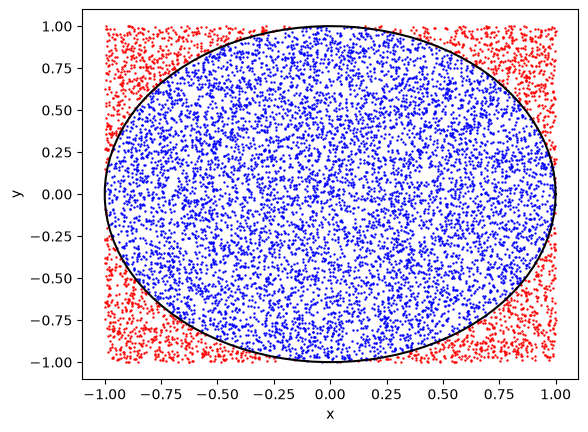

In [3]:
theta = np.linspace(0, 2*np.pi, 100)

plt.figure()
plt.scatter(x_circle_vals, y_circle_vals, c='b', s=0.5)
plt.scatter(x_no_circle_vals, y_no_circle_vals, c='r', s=0.5)
plt.plot(np.cos(theta), np.sin(theta), 'k')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

In [4]:
N = 100000
for i in range(N):
    s = unif.rvs()
    call = f(s)
    sample_sum += call
    
sample_sum /= N
print("integral as estimated from 100,000 Samples: {}".format(sample_sum))

integral as estimated from 100,000 Samples: 0.33229512766850827


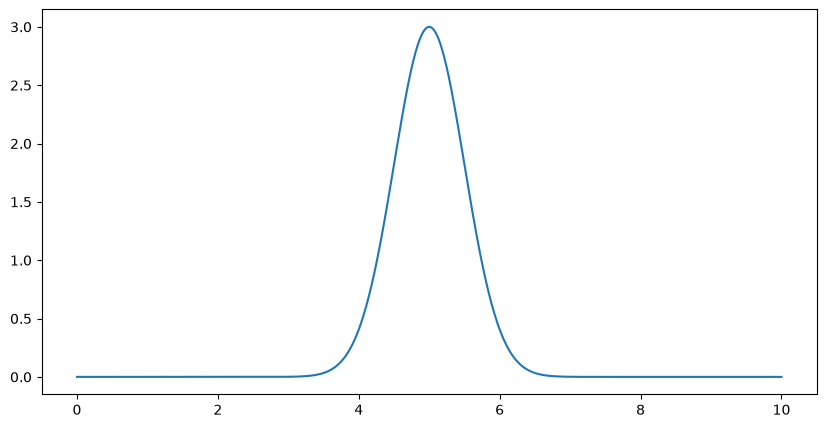

In [5]:
def f2(x):
    out = 3 * np.exp(-(x-5.)**2/(2*0.5**2))
    return out

xx = np.linspace(0,10,1000)
y = f2(xx)
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(xx,y);

In [6]:
#f(x) is not normalized, it's just something with a gaussian form, as I've multiplied by a constant
def f2(x):
    return 3 * np.exp(-(x-5.)**2/(2*0.5**2))

gauss = stats.norm(5,0.5) #this is my new p(theta)
N=100000
area = []
for i in range(N):
    val = gauss.rvs()
    call = f2(val) / gauss.pdf(val)
    area.append(call)
    
norm_area = np.sum(area) / N

print('Calculated Area: {}'.format(norm_area))

Calculated Area: 3.7599424119464997


In [7]:
area_theoretical = np.sqrt(2*np.pi*0.5**2)*3
area_theoretical

np.float64(3.7599424119465006)

In [24]:
def MCMC(function, init_theta, N):
    theta = np.atleast_1d(np.asarray(init_theta, dtype=float))
    theta_chain = [theta.copy()]

    for i in range(N):
        theta_prime = stats.multivariate_normal.rvs(mean=theta, cov=np.eye(len(theta)))
        theta_prime = np.atleast_1d(theta_prime)

        r = np.random.uniform()

        log_diff = np.log(function(theta_prime))-np.log(function(theta))

        if np.log(r) < log_diff:
                theta = theta_prime
        theta_chain.append(theta.copy())

        

    return np.array(theta_chain)

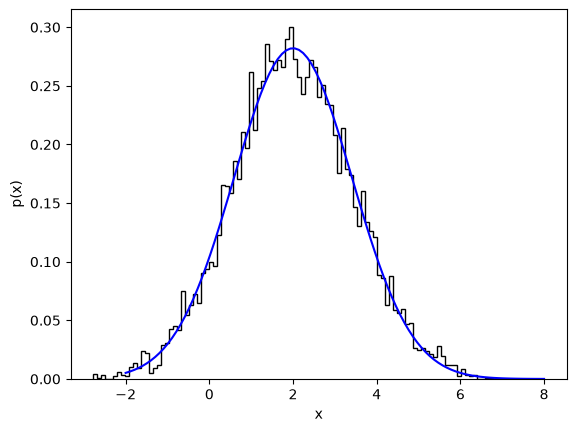

In [25]:
def gaussian(x):
    return (1/(np.sqrt(4*np.pi)))*np.exp((-((x-2)/np.sqrt(2))**2)/2)

n = 10000
x_init = 0
x_vals = np.linspace(-2, 8, 100)

y = gaussian(x_vals)

y_prime = MCMC(gaussian, x_init, n)

plt.hist(y_prime, bins=100, density=True, color='k', histtype='step')
plt.plot(x_vals, y, c = 'b')
plt.xlabel('x')
plt.ylabel('p(x)')
plt.show()

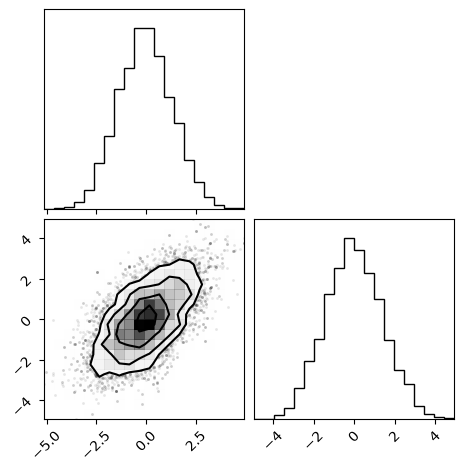

In [30]:
V = np.array([[2,1.2],[1.2,2]])

def twoDgaussian(theta):
    return stats.multivariate_normal.pdf(theta, mean=np.zeros(2), cov=V)



chain = MCMC(twoDgaussian, [0.0, 0.0], 10000)

import corner 
fig = corner.corner(chain)

In [ ]:
class MetropolisHastings():
    def __init__(self):
        self.Uniform = stats.uniform()
        self.theta_chain = []
        pass
    def set_proposal_sigma(self, theta):
        self.theta = theta
        N = len(self.theta)
        matrix = theta**2 * np.eye(N)
        self.proposal_distribution = stats.multivariate_normal(cov=np.zeros((N, N)) + matrix)
    def set_target_distribution(self, function):
        self.target_distribution = function
    def initialize(self, theta_init, nsteps):
        self.theta_init = theta_init
        self.nsteps = nsteps
    def sample(self):
        self.theta_chain = [self.theta_init.copy()]
        for i in range(self.nsteps):
            theta_prime = stats.multivariate_normal.rvs(mean=self.theta_init, cov=np.eye(len(self.theta_init)))
            theta_prime = np.atleast_1d(theta_prime)
            
            r = np.random.uniform()
            
            log_diff = np.log(self.target_distribution(theta_prime))-np.log(self.target_distribution(self.theta_init))
            
            if np.log(r) < log_diff:
                self.theta_init = theta_prime
            self.theta_chain.append(self.theta_init.copy())
    def plot_corner(self):
        fig = corner.corner(np.array(self.theta_chain))

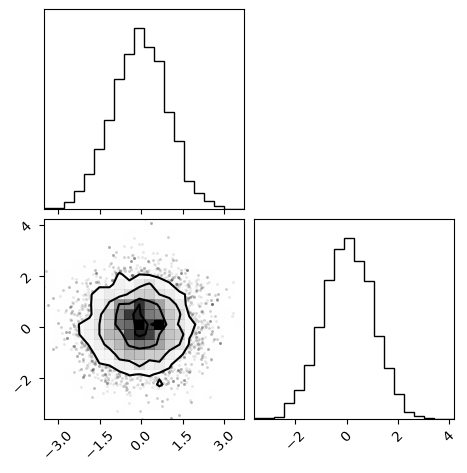

In [80]:
def func_to_integrate(theta):
    a,b = theta
    return np.exp(-(a**2+b**2)/2)

sampler = MetropolisHastings()

sampler.set_proposal_sigma(np.array([1,2])) #2D since my function above takes a 2d theta

sampler.set_target_distribution(func_to_integrate)

sampler.initialize(theta_init=[1,1],nsteps=10000)

sampler.sample()

sampler.plot_corner()